In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

In [3]:
df = pd.read_csv("Womens Clothing E-Commerce Reviews.csv")

In [5]:
df

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses
...,...,...,...,...,...,...,...,...,...,...,...
23481,23481,1104,34,Great dress for many occasions,I was very happy to snag this dress at such a ...,5,1,0,General Petite,Dresses,Dresses
23482,23482,862,48,Wish it was made of cotton,"It reminds me of maternity clothes. soft, stre...",3,1,0,General Petite,Tops,Knits
23483,23483,1104,31,"Cute, but see through","This fit well, but the top was very see throug...",3,0,1,General Petite,Dresses,Dresses
23484,23484,1084,28,"Very cute dress, perfect for summer parties an...",I bought this dress for a wedding i have this ...,3,1,2,General,Dresses,Dresses


In [6]:
df.columns

Index(['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating',
       'Recommended IND', 'Positive Feedback Count', 'Division Name',
       'Department Name', 'Class Name'],
      dtype='str')

In [7]:
df.shape

(23486, 11)

In [8]:
df.isnull().sum()

Unnamed: 0                    0
Clothing ID                   0
Age                           0
Title                      3810
Review Text                 845
Rating                        0
Recommended IND               0
Positive Feedback Count       0
Division Name                14
Department Name              14
Class Name                   14
dtype: int64

In [10]:
categorical_colum = [
    'Title','Review Text','Recommended IND','Division Name','Department Name','Class Name','Rating'
]

In [19]:
for col in categorical_colum:
    print("\nfrequency distribution:",col)
    print("\n", df[col].value_counts())


frequency distribution: Title

 Title
Love it!                                              136
Beautiful                                              95
Love                                                   88
Love!                                                  84
Beautiful!                                             72
                                                     ... 
Great dress for many occasions                          1
Wish it was made of cotton                              1
Cute, but see through                                   1
Very cute dress, perfect for summer parties and we      1
Please make more like this one!                         1
Name: count, Length: 13993, dtype: int64

frequency distribution: Review Text

 Review Text
Perfect fit and i've gotten so many compliments. i buy all my suits from here now!                                                                                                                                                     

In [21]:
df_encoded = df.copy()
for col in categorical_colum:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col].fillna("unknown").astype(str))
df_encoded.head()

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,13992,245,3,1,0,2,2,5
1,1,1080,34,13992,13177,4,1,4,0,1,3
2,2,1077,60,11448,4925,2,0,0,0,1,3
3,3,1049,50,8052,7405,4,1,0,1,0,13
4,4,847,47,4362,20322,4,1,6,0,4,0


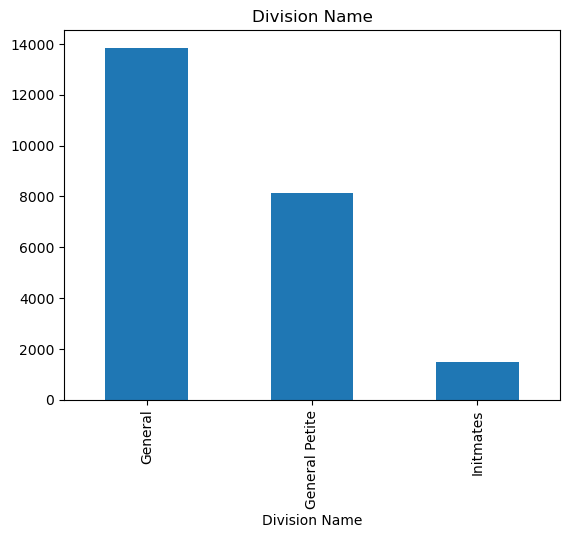

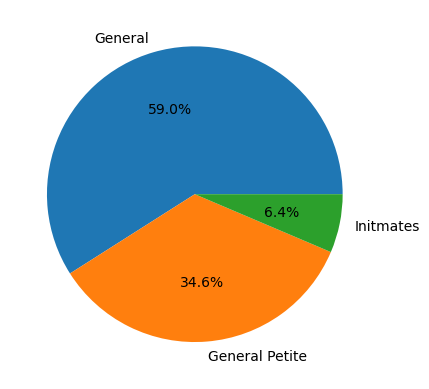

In [27]:
df['Division Name'].value_counts().plot(kind='bar',title="Division Name")
plt.show()
df['Division Name'].value_counts().plot(kind='pie',autopct="%1.1f%%")
plt.show()

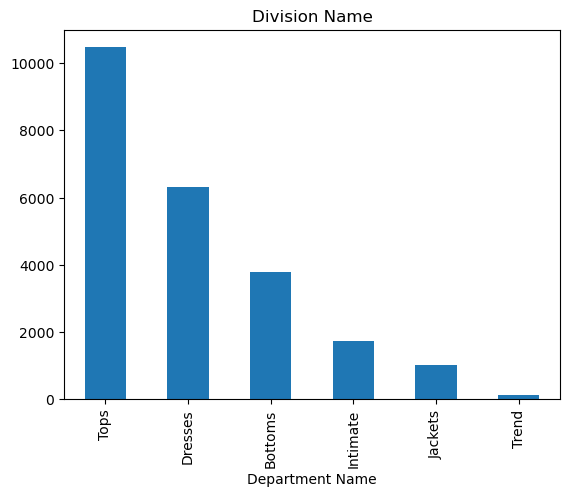

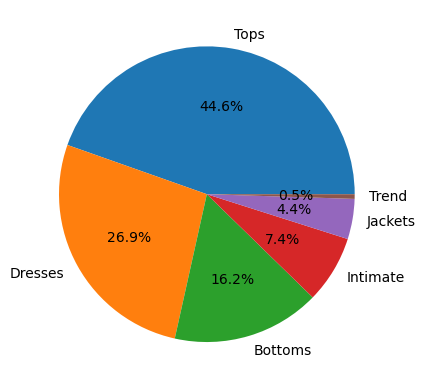

In [28]:
df['Department Name'].value_counts().plot(kind='bar',title="Division Name")
plt.show()
df['Department Name'].value_counts().plot(kind='pie',autopct="%1.1f%%")
plt.show()

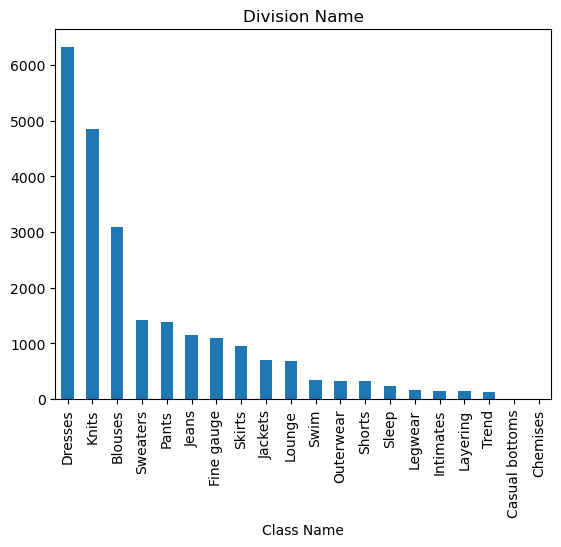

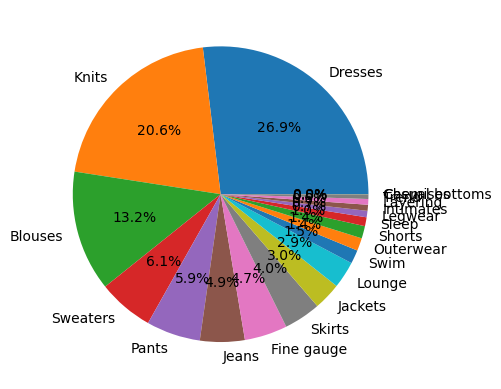

In [29]:
df['Class Name'].value_counts().plot(kind='bar',title="Division Name")
plt.show()
df['Class Name'].value_counts().plot(kind='pie',autopct="%1.1f%%")
plt.show()

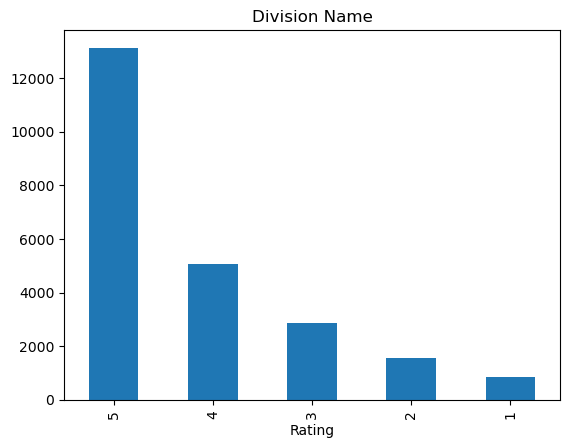

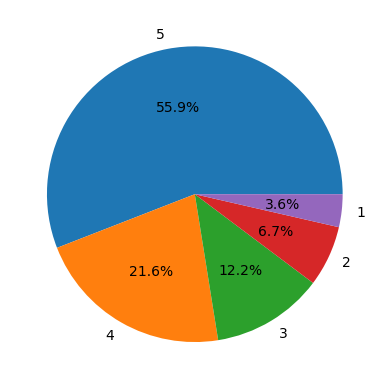

In [31]:
df['Rating'].value_counts().plot(kind='bar',title="Division Name")
plt.show()
df['Rating'].value_counts().plot(kind='pie',autopct="%1.1f%%")
plt.show()

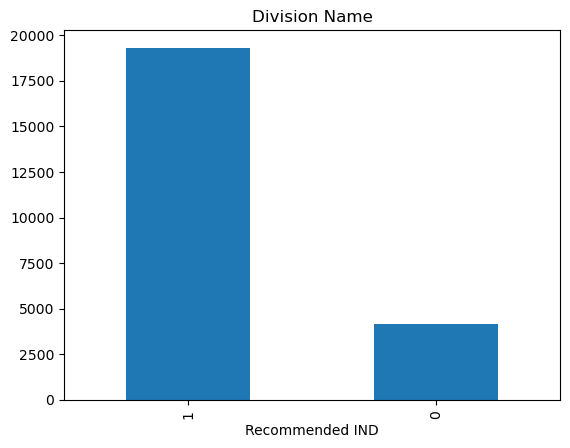

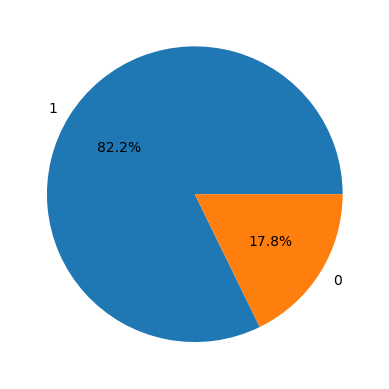

In [32]:
df['Recommended IND'].value_counts().plot(kind='bar',title="Division Name")
plt.show()
df['Recommended IND'].value_counts().plot(kind='pie',autopct="%1.1f%%")
plt.show()

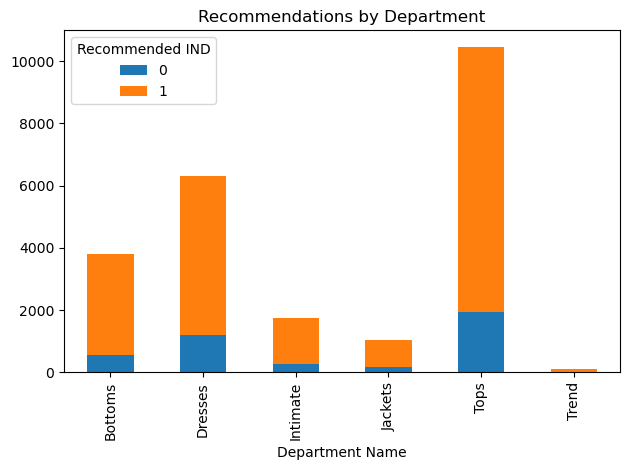

In [36]:
pd.crosstab(df['Department Name'],df['Recommended IND']).plot(kind='bar',stacked=True)
plt.title("Recommendations by Department")
plt.tight_layout()
plt.show()

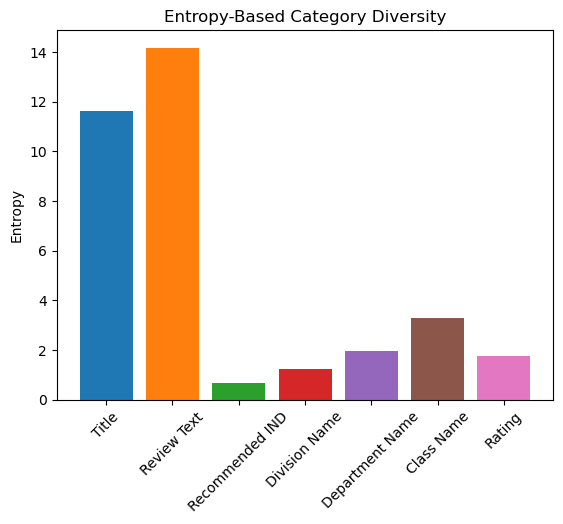

In [42]:
for col in cat_cols:
    p = df[col].fillna("Unknown").value_counts(normalize=True)
    entropy = -(p * np.log2(p)).sum()

    plt.bar(col, entropy)

plt.title("Entropy-Based Category Diversity")
plt.ylabel("Entropy")
plt.xticks(rotation=45)
plt.show()